# Classification des tumeurs cérébrales avec un Vision Transformer (ViT)

**Binôme :** Abdelkarim Qhatti & Rani Ben Messaoud  
**Dataset :** [Brain Tumor MRI Scan – Hugging Face](https://huggingface.co/datasets/Simezu/brain-tumour-MRI-scan)  
**Dépôt GitHub :** [Brain-Tumor-MRI-DL](https://github.com/KareemChatti/Brain-Tumor-MRI-DL)

## Objectif du notebook

Construire un modèle de classification d'images IRM en utilisant un **Vision Transformer pré-entraîné**. Le notebook suit une démarche simple :

1. Installer et importer les bibliothèques.
2. Télécharger et découvrir le dataset.
3. Préparer les images et les jeux de données.
4. Charger un ViT pré-entraîné et l'adapter à nos 4 classes.
5. Entraîner le modèle et suivre ses performances.
6. Évaluer le modèle sur les images de test.
7. Tester une prédiction sur une image et sauvegarder le modèle.



## 1. Installation des bibliothèques

Nous utilisons TensorFlow/Keras pour l'entraînement, KerasHub pour charger le Vision Transformer pré-entraîné, Hugging Face Hub pour télécharger les images et scikit-learn pour les métriques d'évaluation.

**Environnement conseillé :** Google Colab avec accélérateur GPU (Runtime → Change runtime type → T4 GPU).

In [ ]:
!pip install -q -U keras-hub huggingface_hub scikit-learn seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.33.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


## 2. Importation et configuration

In [ ]:
import os
import gc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
import keras_hub

from huggingface_hub import snapshot_download
from sklearn.metrics import classification_report, confusion_matrix

keras.utils.set_random_seed(42)
print("TensorFlow :", tf.__version__)
print("Keras :", keras.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
Keras : 3.15.1
GPU disponible : []


## 3. Téléchargement du dataset

Le dataset contient des images réparties en quatre catégories :

- `1-notumor` : absence de tumeur ;
- `2-glioma` : gliome ;
- `3-meningioma` : méningiome ;
- `4-pituitary` : tumeur hypophysaire.

Le dépôt Hugging Face organise les images en deux dossiers : `Training` et `Testing`. Nous conservons le dossier `Testing` pour l'évaluation finale. Le dossier `Training` sera divisé en entraînement et validation.

In [ ]:
DATASET_REPO = "Simezu/brain-tumour-MRI-scan"

dataset_dir = snapshot_download(
    repo_id=DATASET_REPO,
    repo_type="dataset",
    allow_patterns=["Training/**", "Testing/**"]
)

train_dir = os.path.join(dataset_dir, "Training")
test_dir = os.path.join(dataset_dir, "Testing")

print("Dossier dataset :", dataset_dir)
print("Training existe :", os.path.isdir(train_dir))
print("Testing existe :", os.path.isdir(test_dir))
print("Sous-dossiers Training :", sorted(os.listdir(train_dir)))
print("Sous-dossiers Testing :", sorted(os.listdir(test_dir)))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7023 files:   0%|          | 0/7023 [00:00<?, ?it/s]

Dossier dataset : /root/.cache/huggingface/hub/datasets--Simezu--brain-tumour-MRI-scan/snapshots/54cf3f167d33fd6e99e31e1ff2733852ace08b75
Training existe : True
Testing existe : True
Sous-dossiers Training : ['1-notumor', '2-glioma', '3-meningioma', '4-pituitary']
Sous-dossiers Testing : ['1-notumor', '2-glioma', '3-meningioma', '4-pituitary']


## 4. Paramètres et chargement des images

Le ViT choisi attend des images de **224 × 224 pixels**. Nous utilisons des lots de 8 images pour limiter la consommation mémoire du GPU. Si vous rencontrez une erreur de mémoire, réduisez `BATCH_SIZE` à 4 ou 2.

La validation est créée à partir du dossier `Training` (20 %). Le dossier `Testing` reste indépendant.

In [ ]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_ds = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int"
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes :", class_names)
print("Nombre de classes :", NUM_CLASSES)
print("Mapping des labels :", {i: name for i, name in enumerate(class_names)})

assert NUM_CLASSES == 4, "Le dataset devrait contenir exactement 4 classes."
assert val_ds.class_names == class_names
assert test_ds.class_names == class_names

Found 5712 files belonging to 4 classes.
Using 4570 files for training.
Found 5712 files belonging to 4 classes.
Using 1142 files for validation.
Found 1311 files belonging to 4 classes.
Classes : ['1-notumor', '2-glioma', '3-meningioma', '4-pituitary']
Nombre de classes : 4
Mapping des labels : {0: '1-notumor', 1: '2-glioma', 2: '3-meningioma', 3: '4-pituitary'}


## 5. Exploration des données

Avant l'entraînement, affichons quelques images pour vérifier le chargement des fichiers et l'association entre les images et leurs étiquettes.

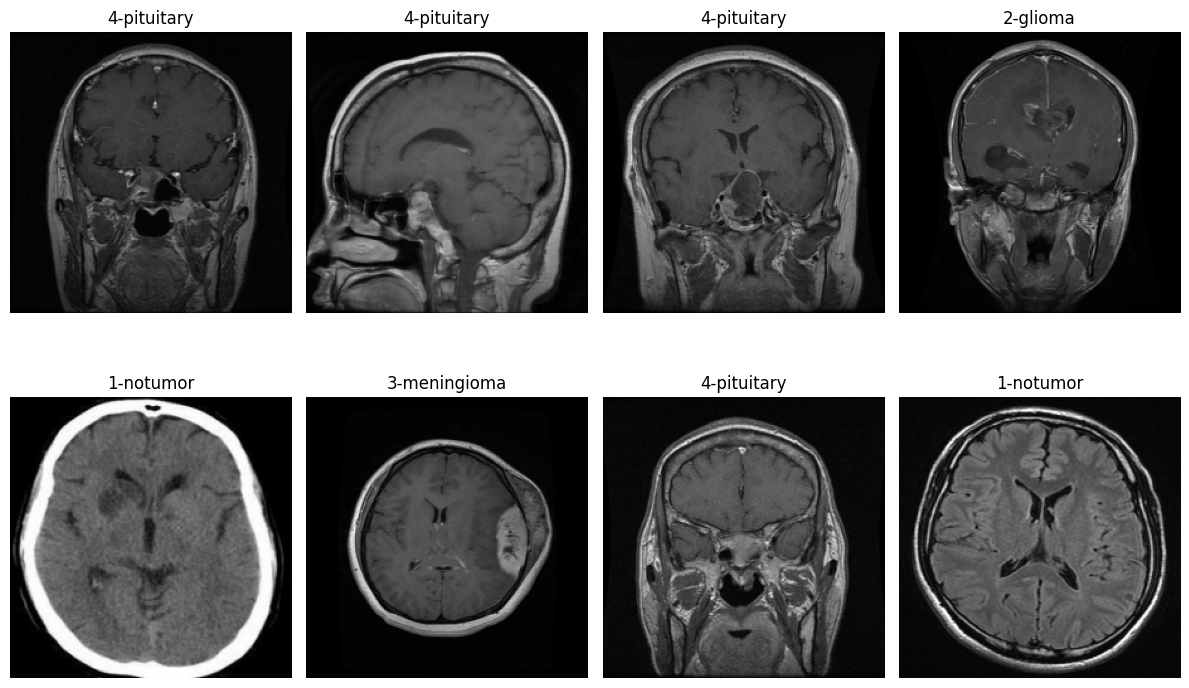

In [ ]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    n = min(8, len(images))
    for i in range(n):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

### Répartition des classes

On compte les images par classe dans chacun des trois ensembles. Cela permet de repérer un éventuel déséquilibre.

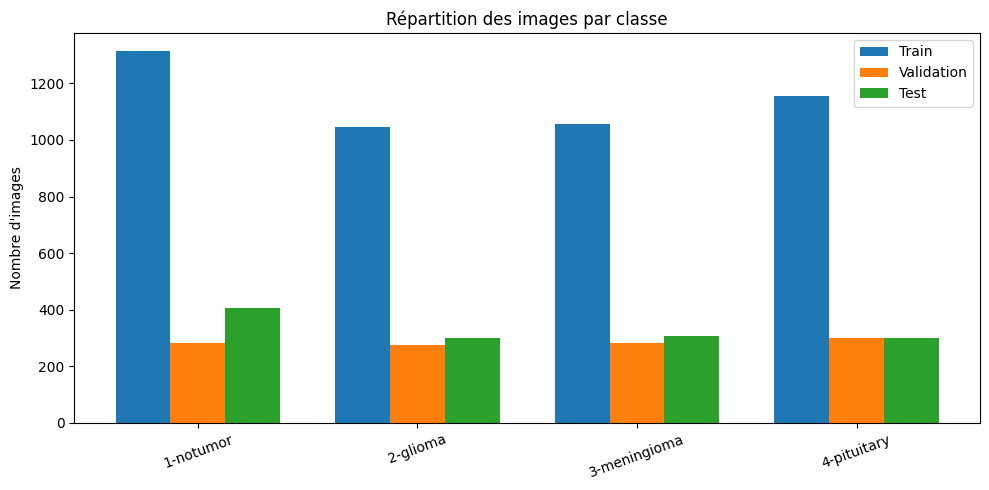

In [ ]:
def compter_classes(dataset, nombre_classes):
    counts = np.zeros(nombre_classes, dtype=int)
    for _, labels in dataset:
        valeurs, effectifs = np.unique(labels.numpy(), return_counts=True)
        counts[valeurs] += effectifs
    return counts

counts_train = compter_classes(train_ds, NUM_CLASSES)
counts_val = compter_classes(val_ds, NUM_CLASSES)
counts_test = compter_classes(test_ds, NUM_CLASSES)

x = np.arange(NUM_CLASSES)
width = 0.25

plt.figure(figsize=(10, 5))
plt.bar(x - width, counts_train, width, label="Train")
plt.bar(x, counts_val, width, label="Validation")
plt.bar(x + width, counts_test, width, label="Test")
plt.xticks(x, class_names, rotation=20)
plt.ylabel("Nombre d'images")
plt.title("Répartition des images par classe")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Optimisation du chargement des données

`prefetch` prépare les prochains lots pendant que le modèle traite le lot courant. Cela peut rendre l'entraînement plus fluide.

In [11]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

## 7. Comprendre le modèle ViT choisi

Nous utilisons le preset `vit_base_patch16_224_imagenet` :

- **224 × 224** : résolution d'entrée ;
- **16 × 16** : taille d'un patch ;
- **14 × 14 = 196** : nombre de patchs par image ;
- le modèle ajoute un token spécial `[CLS]` pour représenter l'image entière ;
- les poids pré-entraînés proviennent d'un apprentissage sur ImageNet.

Le modèle pré-entraîné connaît déjà des caractéristiques visuelles générales. Nous remplaçons sa tête de classification pour prédire nos quatre catégories d'IRM.

In [ ]:
PRESET = "vit_base_patch16_224_imagenet"

vit_model = keras_hub.models.ViTImageClassifier.from_preset(
    PRESET,
    num_classes=NUM_CLASSES
)

print("Nombre total de paramètres :", f"{vit_model.count_params():,}")
vit_model.summary()

Nombre total de paramètres : 85,801,732


Preprocessor: "vi_t_image_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ vi_t_image_converter (ViTImageConverter)                      │                   Image size: (224, 224) │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "vi_t_image_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                  ┃ Output Shape                       ┃             Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ images (InputLayer)                           │ (None, 224, 224, 3)                │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ vi_t_backbone (ViTBackbone)                   │ (None, 197, 768)                   │          85,798,656 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ get_item (GetItem)                            │ (None, 768)                        │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ output_dropout (Dropout)                      │ (None, 768)                        │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ predictions (Dense)                           │ (None, 4)                          │               3,076 │
└───────────────────────────────────────────────┴────────────────────────────────────┴─────────────────────┘

 Total params: 85,801,732 (327.31 MB)

 Trainable params: 85,801,732 (327.31 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Compilation du modèle

Nous utilisons :

- **Adam** comme optimiseur ;
- un taux d'apprentissage faible (`2e-5`) pour ajuster prudemment les poids pré-entraînés ;
- `SparseCategoricalCrossentropy(from_logits=True)` car les labels sont des entiers (0 à 3) et le modèle renvoie des logits ;
- `accuracy` pour suivre la proportion de prédictions correctes.

Cette approche correspond à un **fine-tuning** : le modèle pré-entraîné est adapté à notre tâche de classification à quatre classes.

In [12]:
vit_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

## 9. Entraînement

Nous limitons le nombre initial d'époques à 5. `EarlyStopping` arrête l'entraînement si la perte de validation ne s'améliore plus et restaure les meilleurs poids observés.

Si l'entraînement est trop long, utilisez un GPU et/ou réduisez le nombre d'époques.

In [10]:
EPOCHS = 5

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7
    )
]

history = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 29/572 ━━━━━━━━━━━━━━━━━━━━ 2:50:48 19s/step - accuracy: 0.6638 - loss: 0.8612

KeyboardInterrupt: 

### Visualisation de l'apprentissage

Les courbes permettent de suivre l'évolution de la perte et de l'accuracy sur les données d'entraînement et de validation.

- Si l'accuracy train augmente mais que l'accuracy validation stagne ou baisse, le modèle peut être en surapprentissage.
- Si les deux accuracies restent faibles, le modèle peut nécessiter davantage d'entraînement ou un ajustement des paramètres.

In [ ]:
hist = history.history
epochs_range = range(1, len(hist["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, hist["accuracy"], marker="o", label="Train")
plt.plot(epochs_range, hist["val_accuracy"], marker="o", label="Validation")
plt.title("Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, hist["loss"], marker="o", label="Train")
plt.plot(epochs_range, hist["val_loss"], marker="o", label="Validation")
plt.title("Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Évaluation sur le jeu de test

Le jeu de test n'a pas été utilisé pendant l'entraînement ni pour choisir les hyperparamètres. Il sert à estimer les performances finales sur des images mises de côté.

In [ ]:
test_loss, test_accuracy = vit_model.evaluate(test_ds, verbose=1)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f} ({test_accuracy:.2%})")

### Prédictions et rapport de classification

Le rapport fournit, pour chaque classe :

- **precision** : parmi les images prédites dans cette classe, quelle proportion est correcte ;
- **recall** : parmi les images réellement de cette classe, quelle proportion a été retrouvée ;
- **f1-score** : moyenne harmonique de la précision et du rappel.

Ces mesures sont importantes : une accuracy globale seule ne décrit pas toutes les erreurs possibles.

In [ ]:
y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)

logits = vit_model.predict(test_ds, verbose=1)
y_pred = np.argmax(logits, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

### Matrice de confusion

La diagonale représente les prédictions correctes. Les autres cases indiquent les confusions entre catégories.

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion — jeu de test")
plt.tight_layout()
plt.show()

## 11. Examiner quelques prédictions

Affichons quelques images du jeu de test avec leur classe réelle, la classe prédite et le niveau de confiance associé à la prédiction.

In [ ]:
# Récupérer un lot d'images du jeu de test
images_sample, labels_sample = next(iter(test_ds))
logits_sample = vit_model.predict(images_sample, verbose=0)
probs_sample = tf.nn.softmax(logits_sample, axis=1).numpy()
pred_sample = np.argmax(probs_sample, axis=1)

plt.figure(figsize=(14, 8))
for i in range(min(8, len(images_sample))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images_sample[i].numpy().astype("uint8"))
    true_name = class_names[int(labels_sample[i])]
    pred_name = class_names[int(pred_sample[i])]
    confidence = float(np.max(probs_sample[i]))
    color = "green" if true_name == pred_name else "red"
    plt.title(
        f"Réel : {true_name}\nPrédit : {pred_name}\nConfiance : {confidence:.1%}",
        color=color,
        fontsize=9
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 12. Prédire une image individuelle

Cette fonction reçoit le chemin d'une image, la redimensionne à 224 × 224, puis affiche la classe prédite et les probabilités estimées pour les quatre classes.

Remplacez le chemin d'exemple par le chemin d'une image que vous souhaitez tester.

In [ ]:
def predire_image(image_path):
    image = keras.utils.load_img(image_path, target_size=IMAGE_SIZE)
    image_array = keras.utils.img_to_array(image)
    image_batch = np.expand_dims(image_array, axis=0)

    logits = vit_model.predict(image_batch, verbose=0)
    probabilities = tf.nn.softmax(logits, axis=1).numpy()[0]

    predicted_index = int(np.argmax(probabilities))

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prédiction : {class_names[predicted_index]} "
        f"({probabilities[predicted_index]:.1%})"
    )
    plt.show()

    for name, probability in zip(class_names, probabilities):
        print(f"{name:15s} : {probability:.2%}")

# Exemple : choisir une image existante du dossier Testing
example_class = class_names[0]
example_folder = os.path.join(test_dir, example_class)
example_files = [
    os.path.join(example_folder, f)
    for f in os.listdir(example_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

if example_files:
    predire_image(example_files[0])
else:
    print("Aucune image trouvée dans :", example_folder)

## 13. Sauvegarder le modèle

Le modèle entraîné peut être sauvegardé au format Keras (`.keras`) puis rechargé ultérieurement.

In [ ]:
model_path = "vit_brain_tumor_classifier.keras"
vit_model.save(model_path)
print("Modèle sauvegardé :", model_path)

# Pour recharger le modèle plus tard :
# loaded_model = keras.models.load_model(model_path)

## 14. Conclusion

Dans ce notebook, nous avons suivi une chaîne complète de classification avec un Vision Transformer :

1. téléchargement et exploration des images IRM ;
2. séparation des données en entraînement, validation et test ;
3. adaptation d'un ViT pré-entraîné à quatre classes ;
4. entraînement par fine-tuning ;
5. évaluation avec accuracy, precision, recall, F1-score et matrice de confusion ;
6. test d'une prédiction individuelle et sauvegarde du modèle.
